In [33]:
import numpy as np
from scipy.optimize import minimize

np.random.seed(2)

## 1. Data generation (Newton's method)

Newton's method computes the correct root for each equation, giving the computer the right answers to learn from.
Nothing here knows Cardano's
formula. We keep the one-real-root regime so the target is a single
well-defined value.

In [34]:
def newton_root(p, q, max_iter=200, tol=1e-14):
    """Solve x^3 + p*x + q = 0 numerically. This is the data source."""
    x = 1.0 + max(abs(p), abs(q))
    for _ in range(max_iter):
        f  = x**3 + p*x + q
        df = 3*x**2 + p
        if abs(df) < 1e-12:
            return None
        x_new = x - f/df
        if abs(x_new - x) < tol:
            if abs(x_new**3 + p*x_new + q) < 1e-8:
                return x_new
            return None
        x = x_new
    return None

def make_dataset(n):
    P, Q, U = [], [], []
    while len(P) < n:
        p = np.random.uniform(-5, 5)
        q = np.random.uniform(-5, 5)
        if (q/2)**2 + (p/3)**3 > 0.01:        # one-real-root regime
            u = newton_root(p, q)
            if u is not None:
                P.append(p); Q.append(q); U.append(u)
    return np.array(P), np.array(Q), np.array(U)

# Separate train and test sets -> we measure GENERALIZATION, not memorization.
p_tr, q_tr, u_tr = make_dataset(2000)
p_te, q_te, u_te = make_dataset(500)
print("train:", len(u_tr), " test:", len(u_te))

train: 2000  test: 500


## Symbolic regression with discovered sparsity

We gave the computer a formula shaped like Cardano's (two cube roots with a square root inside), but instead of writing in the right terms by hand, we stuffed in every possible p-and-q term up to the third power and let the computer decide which ones matter. An L1 (lasso-style) penalty during fitting pushes useless coefficients toward zero, so the *sparsity
pattern itself is learned from the data*. Whatever structure remains was
discovered, not assumed.

In [35]:
def hypothesis(xi, p, q):
    L = xi[1] + xi[2]*p + xi[3]*q
    S = (xi[4] + xi[5]*p + xi[6]*q
         + xi[7]*p**2 + xi[8]*q**2 + xi[9]*p*q
         + xi[10]*p**3 + xi[11]*q**3)
    S = np.maximum(S, 1e-12)
    return xi[0] * (np.cbrt(L + np.sqrt(S)) + np.cbrt(L - np.sqrt(S)))

def fit_error(xi):
    g = hypothesis(xi, p_tr, q_tr)
    return 0.5 * np.mean((g - u_tr)**2)

def objective_l1(xi, lam=1e-4):
    # fit error, plus a penalty that shrinks every coefficient except the scale one
    return fit_error(xi) + lam * np.sum(np.abs(xi[1:]))

In [36]:
# Stage 1: run many restarts with the L1 penalty to find a solution with few nonzero terms
best, best_x = np.inf, None
for _ in range(30):   
    r = minimize(objective_l1, np.random.randn(12), method="Nelder-Mead",
                 options={"maxiter": 40000, "xatol": 1e-12, "fatol": 1e-14})
    if r.fun < best:
        best, best_x = r.fun, r.x

# Stage 2: polish WITHOUT the penalty so surviving coefficients are exact.
x = best_x
for _ in range(8):
    x = minimize(fit_error, x, method="Nelder-Mead",
                 options={"maxiter": 40000, "xatol": 1e-14, "fatol": 1e-16}).x
    x = minimize(fit_error, x, method="L-BFGS-B",
                 options={"maxiter": 40000, "ftol": 1e-16, "gtol": 1e-12}).x

print("Route B  train fit error:", fit_error(x))
print("Route B  test  fit error:",
      0.5*np.mean((hypothesis(x, p_te, q_te) - u_te)**2))

Route B  train fit error: 7.897913844790217e-05
Route B  test  fit error: 8.864356464931882e-05


In [37]:
def normalize_params(params):
    params = params.copy()
    lam = -0.5 / params[3]
    params[1:4]  *= lam
    params[4:12] *= lam**2
    params[0]    /= np.cbrt(lam)
    return params

learned = normalize_params(x)
np.set_printoptions(suppress=True, precision=8)

sparse = learned.copy()
sparse[np.abs(sparse) < 1e-2] = 0    # threshold below 1/27=0.037 keeps it

print("Discovered sparse parameters:")
print(sparse)
print("\nWhat the data picked out vs. Cardano's known formula:")
print("  xi0  =", sparse[0],  " (Cardano: 1)")
print("  xi3  =", sparse[3],  " (Cardano: -1/2 =", -1/2, ")")
print("  xi8  =", sparse[8],  " (Cardano:  1/4 =", 1/4, ")")
print("  xi10 =", sparse[10], " (Cardano: 1/27 =", 1/27, ")")

Discovered sparse parameters:
[ 0.99900059  0.03287086  0.         -0.5         0.          0.
 -0.03289063  0.          0.25000105  0.          0.03718269  0.        ]

What the data picked out vs. Cardano's known formula:
  xi0  = 0.9990005877352583  (Cardano: 1)
  xi3  = -0.5  (Cardano: -1/2 = -0.5 )
  xi8  = 0.2500010492921012  (Cardano:  1/4 = 0.25 )
  xi10 = 0.03718269096521428  (Cardano: 1/27 = 0.037037037037037035 )


In [38]:
def cardano_real(p, q):
    """The learned real-radical formula. Returns None where it fails."""
    S = q**2/4 + p**3/27          # inner square-root argument
    if S < 0:
        return None               # casus irreducibilis: no real radical value
    r = np.sqrt(S)
    return np.cbrt(-q/2 + r) + np.cbrt(-q/2 - r)

# Sweep a grid over the (p, q) plane
N = 400
ps = np.linspace(-6, 6, N)
qs = np.linspace(-6, 6, N)
PP, QQ = np.meshgrid(ps, qs)
S_grid = QQ**2/4 + PP**3/27
fails  = S_grid < 0               # where the real formula cannot reach

# Verify the failure region is EXACTLY the discriminant region
disc = 4*PP**3 + 27*QQ**2         # = -Delta
match = np.mean(fails == (disc < 0))
print("Fraction of grid where (formula fails) == (4p^3 + 27q^2 < 0):", match)
print("Failure-region fraction of the plane:", fails.mean())

Fraction of grid where (formula fails) == (4p^3 + 27q^2 < 0): 1.0
Failure-region fraction of the plane: 0.1887875


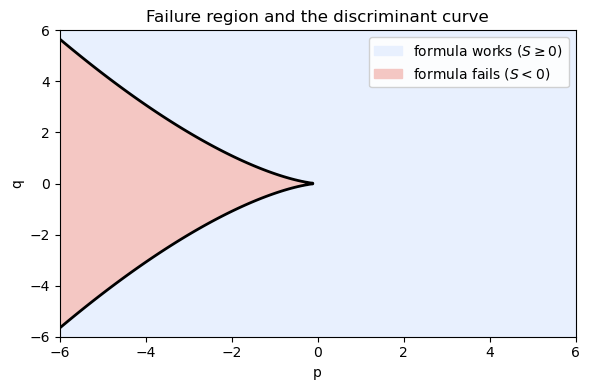

In [39]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.figure(figsize=(6, 4))
plt.contourf(PP, QQ, fails, levels=[-0.5, 0.5, 1.5],
             colors=["#e8f0fe", "#f4c7c3"])
plt.contour(PP, QQ, disc, levels=[0], colors="black", linewidths=2)
plt.xlabel("p"); plt.ylabel("q")
plt.title("Failure region and the discriminant curve")
plt.tight_layout()
blue = mpatches.Patch(color="#e8f0fe", label="formula works ($S \\geq 0$)")
red  = mpatches.Patch(color="#f4c7c3", label="formula fails ($S < 0$)")
plt.legend(handles=[blue, red], loc="upper right", framealpha=0.9)
plt.savefig("cardano_sweep.pdf", bbox_inches="tight")
plt.show()


**Result.** The red region is where the real-radical formula fails. It matches the discriminant being negative (4p^3 + 27q^2 < 0) at every point on the grid, and the black curve marks the exact boundary. Without being told, the method rediscovered the casus irreducibilis: the region of cubics whose real roots cannot be expressed using real radicals alone.